<a href="https://colab.research.google.com/github/raulpek/ADML_project2/blob/main/ADAML_project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install scikit-learn
!pip install matplotlib

In [ ]:
import pandas as pd
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (accuracy_score,
                             confusion_matrix,
                             classification_report,
                             roc_curve, auc)
import matplotlib.pyplot as plt

# Import the IMDB dataset

In [ ]:
splits = {'train': 'plain_text/train-00000-of-00001.parquet', 'test': 'plain_text/test-00000-of-00001.parquet', 'unsupervised': 'plain_text/unsupervised-00000-of-00001.parquet'}
train_df = pd.read_parquet("hf://datasets/stanfordnlp/imdb/" + splits["train"])
test_df = pd.read_parquet("hf://datasets/stanfordnlp/imdb/" + splits["test"])

In [ ]:
text_part = train_df['text']
labels = train_df['label']
train_df.head()

,text,label
0,I rented I AM CURIOUS-YELLOW from my video sto...,0
1,"""I Am Curious: Yellow"" is a risible and preten...",0
2,If only to avoid making this type of film in t...,0
3,This film was probably inspired by Godard's Ma...,0
4,"Oh, brother...after hearing about this ridicul...",0


# Preprocessing

### Train data

In [ ]:
print(f"Number of reviews: {len(text_part)}")
print(f"Number of labels: {len(labels)}")
print(f"Number of unique labels: {len(labels.unique())}")
print(f"Number of unique reviews: {len(text_part.unique())}")
# two labels
# 96 identical reviews, do they have the same labels
df_test = train_df.copy()
n_labels = df_test.groupby("text")["label"].nunique()
counts = df_test["text"].value_counts()
dupli_txt = counts[counts > 1].index
n_labels = n_labels[dupli_txt]
print(f"Duplicate texts with same label: {(n_labels == 1).sum()}")
print(f"Duplicate texts with different label: {(n_labels > 1).sum()}")
# so we simply have 92 duplicates for
# rows already found in the

Number of reviews: 25000
Number of labels: 25000
Number of unique labels: 2
Number of unique reviews: 24904
Duplicate texts with same label: 92
Duplicate texts with different label: 0


In [ ]:
# remove the duplicates
train_df = train_df.drop_duplicates()
# separate the predictors and target
text_part = train_df['text']
labels = train_df['label']

### Test data

In [ ]:
txt_part = test_df['text']
label_prt = test_df['label']

In [ ]:
print(f"Number of reviews: {len(txt_part)}")
print(f"Number of labels: {len(label_prt)}")
print(f"Number of unique labels: {len(label_prt.unique())}")
print(f"Number of unique reviews: {len(txt_part.unique())}")
# two labels
# 96 identical reviews, do they have the same labels
df_ttest = train_df.copy()
n_labels_t = df_ttest.groupby("text")["label"].nunique()
counts_t = df_ttest["text"].value_counts()
dupli_txt_t = counts[counts > 1].index
n_labels_t = n_labels_t[dupli_txt_t]
print(f"Duplicate texts with same label: {(n_labels == 1).sum()}")
print(f"Duplicate texts with different label: {(n_labels > 1).sum()}")
# so we simply have 92 duplicates for
# repeated accross 199 rows

Number of reviews: 25000
Number of labels: 25000
Number of unique labels: 2
Number of unique reviews: 24801
Duplicate texts with same label: 92
Duplicate texts with different label: 0


In [ ]:
test_df = test_df.drop_duplicates()

####  Check if there are same rows both in train and test data

In [ ]:
overlap = train_df.merge(test_df, on="text", how="inner")
print(f"Number of overlapping rows: {len(overlap)}")
# we have 123 rows in common between the two

Number of overlapping rows: 123


In [ ]:
# remove the rows from test data
n_prior = len(test_df)
test_df = test_df[~test_df["text"].isin(train_df["text"])]
test_df = test_df.reset_index(drop=True)
print(f"Number of shared rows with train: {test_df["text"].isin(train_df["text"]).sum()}")

Number of shared rows with train: 0


In [ ]:
txt_part = test_df['text']
label_prt = test_df['label']

### check the class balance

In [ ]:
frac_labels_tr = labels.value_counts(normalize=True)
frac_labels_te = label_prt.value_counts(normalize=True)
print(f"Fraction of labels in train: {frac_labels_tr}")
print(f"Fraction of labels in test: {frac_labels_te}")
# the distribution of classes are very similar between the train and test
# there is no class imbalance

Fraction of labels in train: label
1    0.500803
0    0.499197
Name: proportion, dtype: float64
Fraction of labels in test: label
1    0.502958
0    0.497042
Name: proportion, dtype: float64


# Logistic Model

### Library implemented

In [ ]:
### Encode the text with TF-IDF
vectorizer = TfidfVectorizer(max_features=len(train_df), stop_words="english")
X_train = vectorizer.fit_transform(text_part)
X_test = vectorizer.transform(txt_part)
Y_train = labels
Y_test = label_prt

In [ ]:
# library model as baseline
clf = LogisticRegression(max_iter=10000, random_state=0)
clf.fit(X_train, Y_train)
y_pred = clf.predict(X_test)
print(f"Accuracy: {round(accuracy_score(Y_test, y_pred),4)}")

Accuracy: 0.8798


In [ ]:
tn, fp, fn, tp = confusion_matrix(Y_test, y_pred).ravel()
print(f"True negatives: {tn}")
print(f"False positives: {fp}")
print(f"False negatives: {fn}")
print(f"True positives: {tp}")

True negatives: 10766
False positives: 1500
False negatives: 1466
True positives: 10946


In [ ]:
class_report = classification_report(Y_test, y_pred, digits=4)
print(class_report)

              precision    recall  f1-score   support

           0     0.8802    0.8777    0.8789     12266
           1     0.8795    0.8819    0.8807     12412

    accuracy                         0.8798     24678
   macro avg     0.8798    0.8798    0.8798     24678
weighted avg     0.8798    0.8798    0.8798     24678



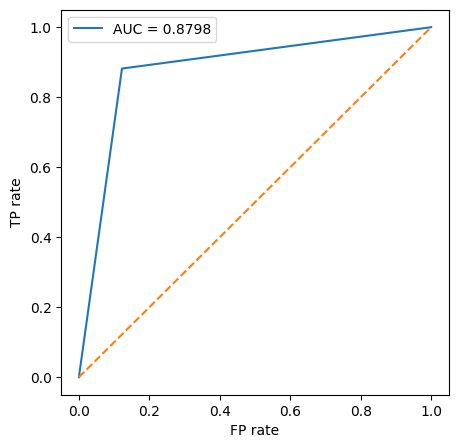

In [ ]:
# AUC ROC
plt.figure(figsize=(5,5))
fpr, tpr, _ = roc_curve(Y_test, y_pred)
roc_auc = auc(fpr, tpr)
plt.plot(fpr, tpr, label=f"AUC = {round(roc_auc, 4)}")
plt.plot([0,1],[0,1], linestyle="--")
plt.xlabel("FP rate")
plt.ylabel("TP rate")
plt.legend()
plt.show()
# diagonal represents a pure guess (0.5)

### Own LR class

In [ ]:
class LogisticModel:
  """
  Logistic Regression Model
  for sentiment classification
  """
  def __init__(self,a):
    self.a = a
  def fit(self,x, y):
    return None
  def predict(self,x):
    return None